# 06 · Interpretación (§4.4: SHAP global y local)

Modelo final fijado en `04_modelado/modelo_final.json` (LightGBM, 6 variables). Aquí no se decide nada; solo se explica el modelo sobre el OOT:

1. **TreeSHAP** en log-odds (si el modelo final fuera un ensemble, promedio simple de los valores SHAP de sus miembros).
2. **Global**: ranking por |SHAP| medio, gráfico de resumen y contraste con la permutación de `03`.
3. **Dependencia**: SHAP frente al valor de cada variable.
4. **Local**: tres vendedoras del OOT con riesgo bajo, medio y alto (sin `id_vendedor`).

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
from sklearn.metrics import roc_auc_score
from src import datos, particion, modelos
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

RAIZ = Path.cwd().parent
IMG = RAIZ / "img"
df = datos.load()
spec = json.loads((RAIZ / "04_modelado/modelo_final.json").read_text())
reg = json.loads((RAIZ / "05_evaluacion/oot_metricas.json").read_text())["oot"]
dev_mask, oot_mask = particion.oot_split(df.mes_rank)
dev, oot = df[dev_mask].reset_index(drop=True), df[oot_mask].reset_index(drop=True)

# models/ no se versiona: si falta el modelo de `05`, se re-entrena con la misma spec y el mismo pool
ruta = datos.ROOT / "models" / "modelo_final.joblib"
ens = joblib.load(ruta) if ruta.exists() else modelos.desde_spec(spec).fit(dev, dev.churn)
X = oot[ens.feats]
p = ens.predict_proba(oot)[:, 1]
auc = roc_auc_score(oot.churn, p)
print(f"modelo: {spec['final']['config']} | variables: {ens.feats}")
print(f"OOT: {len(oot):,} filas ({oot.mes_obs.min():%Y-%m} → {oot.mes_obs.max():%Y-%m})")
print(f"AUC OOT del modelo explicado: {auc:.4f} | registrado en 05: {reg['auc']:.4f}")

modelo: lightgbm | variables: ['compras_hist', 'n_prod_u12', 'monto_cv_u12', 'n_ped_u12', 'monto_u12', 'ticket_prom_u3']
OOT: 879 filas (2025-12 → 2026-03)
AUC OOT del modelo explicado: 0.7931 | registrado en 05: 0.7931


## 1 · Valores SHAP

TreeSHAP explica el log-odds del modelo; se verifica la exactitud local (SHAP + valor base = log-odds predicho).
Con un solo modelo la probabilidad explicada coincide con la predicha; con un ensemble se mediría la diferencia.

In [2]:
vals, bases = [], []
for a, (feats, est, _) in ens.miembros.items():
    assert feats == ens.feats
    e = shap.TreeExplainer(est)(X)
    q = est.predict_proba(X)[:, 1]
    err = np.abs(e.values.sum(1) + e.base_values - np.log(q / (1 - q))).max()
    assert err < 1e-4, f"{a}: SHAP no suma al log-odds"
    vals.append(e.values); bases.append(e.base_values)
    print(f"{a}: exactitud local, error máx {err:.1e}")

sv, base = np.mean(vals, axis=0), float(np.mean(bases))
p_shap = 1 / (1 + np.exp(-(sv.sum(1) + base)))
p_base = 1 / (1 + np.exp(-base))
dif = np.abs(p_shap - p).max()
print(f"valor base: {p_base:.3f} en probabilidad | máx |sigmoide(log-odds medio) − probabilidad media|: {dif:.4f}")

lightgbm: exactitud local, error máx 1.1e-14
valor base: 0.287 en probabilidad | máx |sigmoide(log-odds medio) − probabilidad media|: 0.0000


## 2 · Importancia global

Ranking por |SHAP| medio, signo de la relación (Spearman entre el valor de la variable y su SHAP) y posición de
cada variable en la importancia por permutación de `03` (orden entre las 6 seleccionadas).

In [3]:
perm = json.loads((RAIZ / "03_variables/variables_seleccionadas.json").read_text())["candidatas_orden_permutacion"]
rank = pd.DataFrame({"shap_abs_medio": np.abs(sv).mean(0)}, index=ens.feats)
rank["pct"] = 100 * rank.shap_abs_medio / rank.shap_abs_medio.sum()
rank["rho_valor_shap"] = [pd.Series(sv[:, j]).corr(X[f].reset_index(drop=True), method="spearman") for j, f in enumerate(ens.feats)]
rank = rank.sort_values("shap_abs_medio", ascending=False)
rank["rank_shap"] = range(1, len(rank) + 1)
rank["rank_permutacion"] = pd.Series({f: perm.index(f) for f in rank.index}).rank().astype(int)
rho = rank.rank_shap.corr(rank.rank_permutacion, method="spearman")
print(f"Spearman entre ranking SHAP y ranking por permutación: {rho:.2f}")
rank.round(4)

Spearman entre ranking SHAP y ranking por permutación: 0.14


,shap_abs_medio,pct,rho_valor_shap,rank_shap,rank_permutacion
n_ped_u12,0.2883,21.8552,-0.9899,1,4
monto_u12,0.2670,20.2394,-0.9770,2,5
compras_hist,0.2665,20.2076,-0.9131,3,1
n_prod_u12,0.2109,15.9908,-0.9821,4,2
monto_cv_u12,0.1818,13.7828,0.7357,5,3
ticket_prom_u3,0.1045,7.9241,-0.6880,6,6


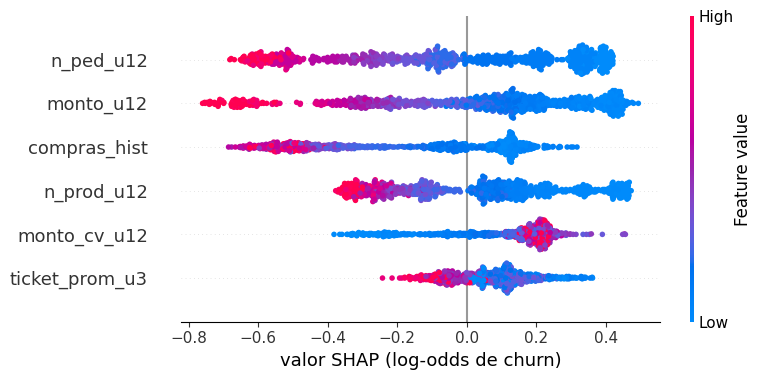

In [4]:
shap.summary_plot(sv, X, show=False)
plt.xlabel("valor SHAP (log-odds de churn)")
plt.savefig(IMG / "shap_resumen.png", dpi=200, bbox_inches="tight"); plt.show()

## 3 · Dependencia

SHAP de cada variable frente a su valor (eje x recortado al percentil 99).

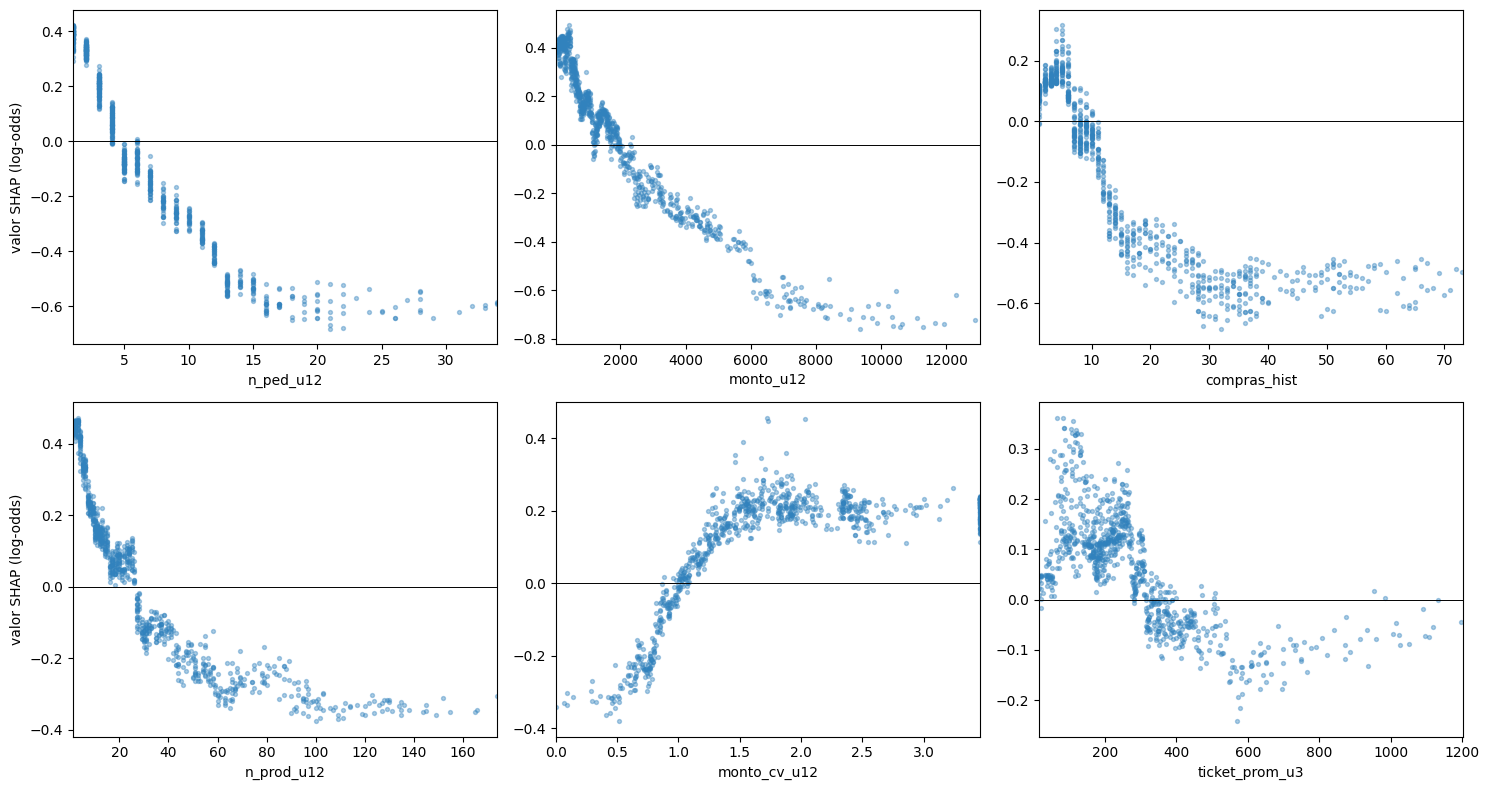

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flat, rank.index):
    ax.scatter(X[f], sv[:, ens.feats.index(f)], s=8, alpha=0.4, c="#3182bd")
    ax.axhline(0, c="k", lw=0.7); ax.set_xlim(X[f].min(), X[f].quantile(0.99)); ax.set_xlabel(f)
for ax in axes[:, 0]: ax.set_ylabel("valor SHAP (log-odds)")
plt.tight_layout(); plt.savefig(IMG / "shap_dependencia.png", dpi=200, bbox_inches="tight"); plt.show()

## 4 · Explicaciones locales

Tres vendedoras del OOT: las más cercanas a los percentiles 5, 50 y 95 del puntaje (la de riesgo alto pertenece al
decil superior). El eje está en probabilidad; rojo eleva el riesgo y azul lo reduce.

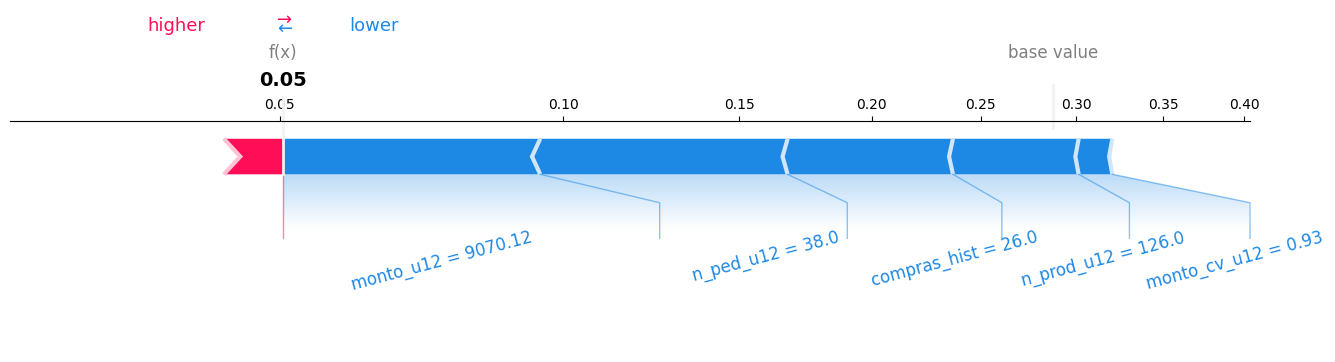

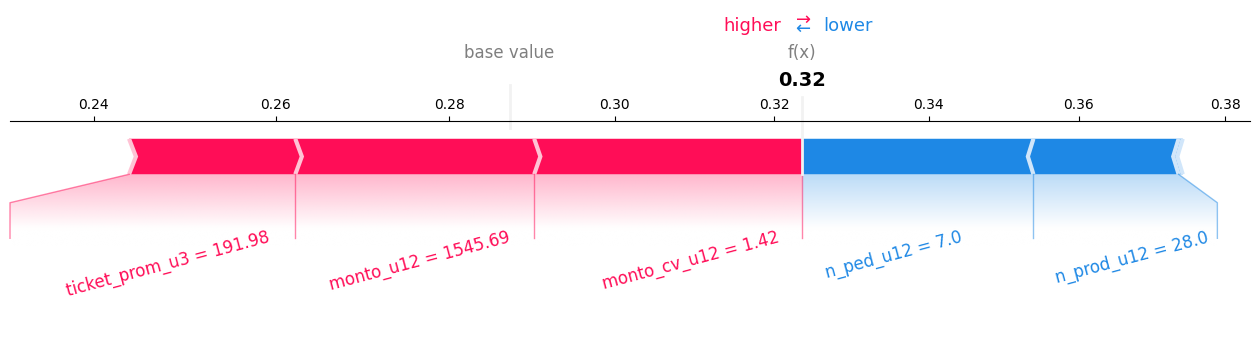

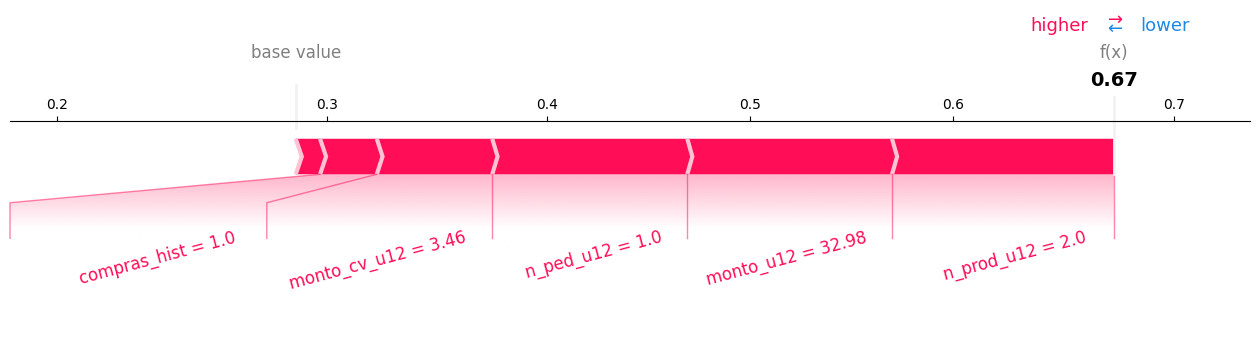

,probabilidad,n_ped_u12,monto_u12,compras_hist,n_prod_u12,monto_cv_u12,ticket_prom_u3
bajo,0.05,38.00 (-0.65),9070.12 (-0.68),26.00 (-0.44),126.00 (-0.33),0.93 (-0.09),179.67 (+0.16)
medio,0.32,7.00 (-0.14),1545.69 (+0.14),8.00 (-0.00),28.00 (-0.09),1.42 (+0.16),191.98 (+0.10)
alto,0.67,1.00 (+0.39),32.98 (+0.41),1.00 (+0.11),2.00 (+0.44),3.46 (+0.23),32.98 (+0.05)


In [6]:
filas = {}
for caso, q in {"bajo": 0.05, "medio": 0.50, "alto": 0.95}.items():
    i = int(np.abs(p_shap - np.quantile(p_shap, q)).argmin())
    shap.force_plot(base, sv[i], X.iloc[i].round(2), link="logit", matplotlib=True, show=False, figsize=(16, 3), text_rotation=15)
    # con eje logit, shap puede dejar el límite inferior < 0 (inválido) y la figura sale en blanco
    ax = plt.gca(); ax.set_xlim(max(ax.get_xlim()[0], min(p_shap[i], p_base) / 2), ax.get_xlim()[1])
    plt.savefig(IMG / f"shap_local_{caso}.png", dpi=200, bbox_inches="tight"); plt.show()
    filas[caso] = {"probabilidad": f"{p_shap[i]:.2f}",
                   **{f: f"{X[f].iat[i]:.2f} ({sv[i, j]:+.2f})" for j, f in enumerate(ens.feats)}}
local = pd.DataFrame(filas).T[["probabilidad", *rank.index]]
local  # valor de la variable (SHAP en log-odds)

## 5 · Exportación

In [7]:
texto = f'''# Interpretación (sem2)

Generado por `06_interpretacion/interpretacion.ipynb`. Modelo: **{spec["final"]["config"]}**, explicado sobre el OOT
({oot.mes_obs.min():%Y-%m} → {oot.mes_obs.max():%Y-%m}, {len(oot):,} filas).

AUC OOT del modelo explicado: {auc:.4f} (registrado en `05`: {reg["auc"]:.4f}).

## 1 · Método
TreeSHAP en log-odds ({len(ens.miembros)} modelo). Valor base: {p_base:.3f} en probabilidad. Diferencia máxima entre la
probabilidad explicada por SHAP y la predicha: {dif:.1e}.

## 2 · Importancia global
{rank.round(4).to_markdown()}

`rho_valor_shap` > 0: valores altos de la variable elevan el riesgo; < 0: lo reducen.
Spearman entre el ranking SHAP y el de permutación de `03` (6 variables): {rho:.2f}.

## 3 · Casos locales (valor de la variable y SHAP en log-odds)
{local.T.to_markdown()}

## Figuras
`img/shap_resumen.png`, `img/shap_dependencia.png`, `img/shap_local_bajo.png`, `img/shap_local_medio.png`,
`img/shap_local_alto.png`.
'''
(RAIZ / "reports" / "interpretacion.md").write_text(texto)
print(texto)

# Interpretación (sem2)

Generado por `06_interpretacion/interpretacion.ipynb`. Modelo: **lightgbm**, explicado sobre el OOT
(2025-12 → 2026-03, 879 filas).

AUC OOT del modelo explicado: 0.7931 (registrado en `05`: 0.7931).

## 1 · Método
TreeSHAP en log-odds (1 modelo). Valor base: 0.287 en probabilidad. Diferencia máxima entre la
probabilidad explicada por SHAP y la predicha: 1.1e-15.

## 2 · Importancia global
|                |   shap_abs_medio |     pct |   rho_valor_shap |   rank_shap |   rank_permutacion |
|:---------------|-----------------:|--------:|-----------------:|------------:|-------------------:|
| n_ped_u12      |           0.2883 | 21.8552 |          -0.9899 |           1 |                  4 |
| monto_u12      |           0.267  | 20.2394 |          -0.977  |           2 |                  5 |
| compras_hist   |           0.2665 | 20.2076 |          -0.9131 |           3 |                  1 |
| n_prod_u12     |           0.2109 | 15.9908 |          -0.9821 |      